Weather Data:


,City,Temperature,Humidity,Wind_Speed,Precipitation,Latitude,Longitude
0,Pune,23.37,79,2.05,0.00,18.5196,73.8553
1,Mumbai,30.13,64,2.77,0.00,19.0144,72.8479
2,Delhi,27.87,43,1.98,0.00,28.6667,77.2167
3,Bangalore,27.01,57,2.84,0.58,12.9762,77.6033
4,Chennai,25.35,88,7.16,0.15,13.0878,80.2785



Average Temperature: 26.746000000000002
Maximum Temperature: 30.13
Minimum Temperature: 23.37
Average Humidity: 66.2
Average Wind Speed: 3.3600000000000003


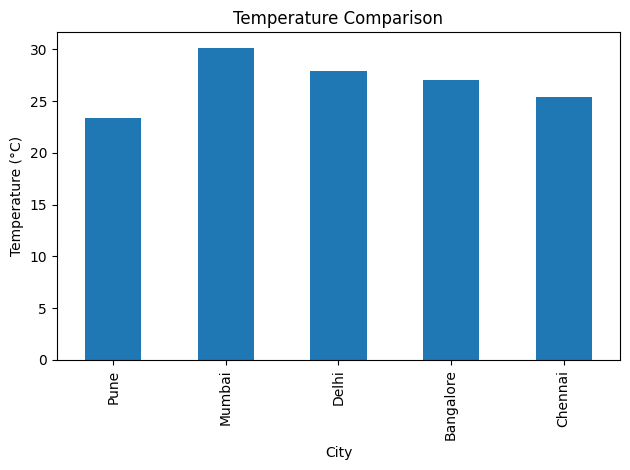

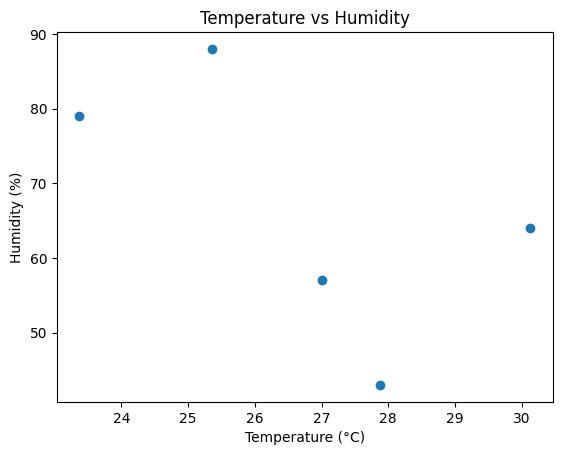

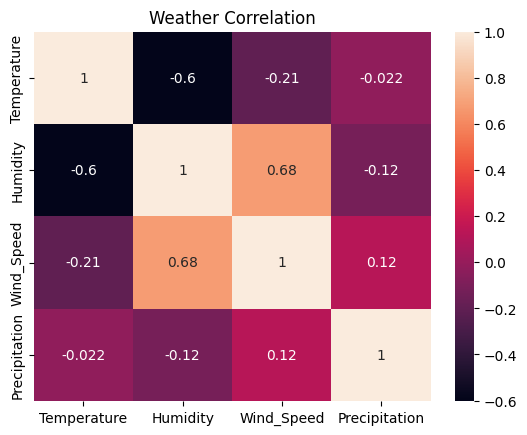

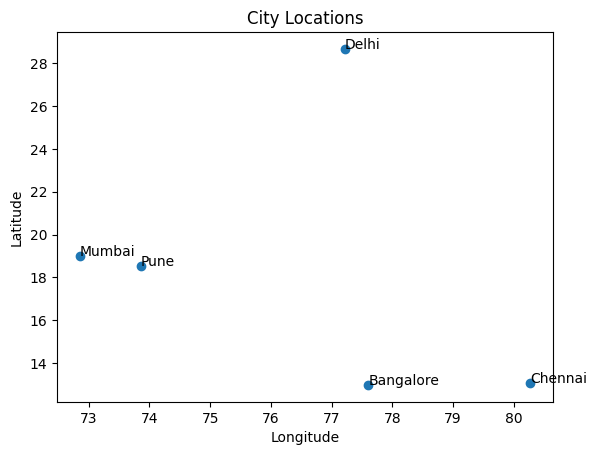

In [1]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

API_KEY = "bf5368148c7573eb0b8c761d051d36e4"
cities = ["Pune", "Mumbai", "Delhi", "Bangalore", "Chennai"]
weather = []

# Fetch weather data
for city in cities:
    url = f"https://api.openweathermap.org/data/2.5/weather?q={city}&appid={API_KEY}&units=metric"

    try:
        response = requests.get(url, timeout=15)
        response.raise_for_status()
        data = response.json()

        weather.append({
            "City": city,
            "Temperature": data["main"]["temp"],
            "Humidity": data["main"]["humidity"],
            "Wind_Speed": data["wind"]["speed"],
            "Precipitation": data.get("rain", {}).get("1h", 0),
            "Latitude": data["coord"]["lat"],
            "Longitude": data["coord"]["lon"]
        })

    except (requests.RequestException, KeyError, ValueError) as e:
        print(f"Error fetching {city}: {e}")

# Create and clean DataFrame
df = pd.DataFrame(weather).dropna()

print("Weather Data:")
display(df)

# Calculate statistics
print("\nAverage Temperature:", df["Temperature"].mean())
print("Maximum Temperature:", df["Temperature"].max())
print("Minimum Temperature:", df["Temperature"].min())
print("Average Humidity:", df["Humidity"].mean())
print("Average Wind Speed:", df["Wind_Speed"].mean())

# Temperature comparison
df.plot(x="City", y="Temperature", kind="bar", legend=False)
plt.ylabel("Temperature (°C)")
plt.title("Temperature Comparison")
plt.tight_layout()
plt.show()

# Temperature vs Humidity
plt.scatter(df["Temperature"], df["Humidity"])
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity (%)")
plt.title("Temperature vs Humidity")
plt.show()

# Correlation heatmap
corr = df[["Temperature", "Humidity", "Wind_Speed", "Precipitation"]].corr()
sns.heatmap(corr, annot=True)
plt.title("Weather Correlation")
plt.show()

# Geographic visualization
plt.scatter(df["Longitude"], df["Latitude"])

for _, row in df.iterrows():
    plt.text(row["Longitude"], row["Latitude"], row["City"])

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("City Locations")
plt.show()